In [1]:
import ete3 
import numpy 
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager
import numpy as np

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
#takes a loss rate u, returns the -log likelihood value of the phyletic pattern
#tree leaves have probability atributes
#p0=1 if gene is absent, 0 if gene is present; p1=1 if gene is present,0 if gene is absent
def get_prob(u):
    te=t.copy()
    while len(list(te.iter_descendants()))>1:
        for node in te.traverse():
        

            if len(node.get_leaf_names())==2:
             
                
                #make a dictionary for p0 and p1 values
                #keys are for p0/p1 and values are a list of the child node values
                ps={0:[],1:[]}
                
                #makes a dictionary for transition probabilities, 
                #keys are 0/1 for loss/gain on the branch from parent to child
                #values are lists of probabilities for each child
                trans={0:[],1:[]}

                for xi in node.iter_descendants():
                 
                    ps[0].append(xi.p0)
                    ps[1].append(xi.p1)
                    #probability of loss
                    trans[0].append(1-np.exp(-u*xi.dist))
                    #probability of retention
                    trans[1].append(np.exp(-u*xi.dist))
                
                #probability of gene absence at a node=probability of gene absence at both descendants
                node.p0=ps[0][0]*ps[0][1]
  
                #probability of gene presence at a node=
                #=sum of probabilities of all possible combinations of presence/absence over child nodes
                sum1=0
                for x in [0,1]:
                    for y in [0,1]:
                        sum1+=ps[x][0]*trans[x][0]*ps[y][1]*trans[y][1]
                node.p1=sum1
             
                #after visiting a node, collapse its children
                for xi in node.iter_descendants():
                    node.remove_child(xi)
         
          
    #gene is inferred to be present at the root 
    return -np.log10(te.p1)

## Test cases
Test simple case in which  of 4 leaves

In [3]:
t=ete3.Tree("((A:1,B:1):1,(C:1,D:1):1);")
tmap={'A':1,'B':1,'C':1,'D':1}
for x in t:
    if x.is_leaf():
        x.p1=int(tmap[x.name]==1)
        x.p0=int(tmap[x.name]==0)

In [4]:
print(t)



      /-A
   /-|
  |   \-B
--|
  |   /-C
   \-|
      \-D


In [5]:
import scipy
m= scipy.optimize.fmin(get_prob, x0=.000001)

Optimization terminated successfully.
         Current function value: 0.000003
         Iterations: 1
         Function evaluations: 2


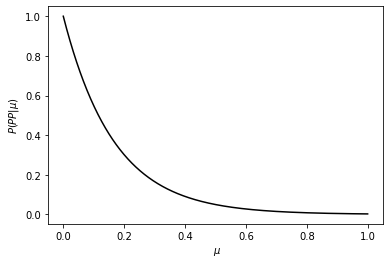

In [6]:
prob=[]
for u in np.linspace(0,1,1000):
    prob.append(get_prob( u))
plt.plot(np.linspace(0,1,1000), 10**-np.array(prob),color='black')
plt.xlabel(r" $\mu$")
plt.ylabel(r"$P(PP|\mu)$")
plt.show()

## Test case of a single loss, with closed-form probability

In [7]:
t=ete3.Tree("((A:1,B:1):1,(C:1,D:1):1);")
tmap={'A':1,'B':1,'C':0,'D':1}
for x in t:
    if x.is_leaf():
        x.p1=int(tmap[x.name]==1)
        x.p0=int(tmap[x.name]==0)

In [8]:

m= scipy.optimize.fmin(get_prob, x0=.10)

Optimization terminated successfully.
         Current function value: 1.174057
         Iterations: 13
         Function evaluations: 26


In [9]:
10**-1.174057

0.06697966946059526

In [10]:
m[0]

0.18234375000000028

/tmp/ipykernel_2534622/3897918740.py:48: RuntimeWarning: divide by zero encountered in log10
  return -np.log10(te.p1)


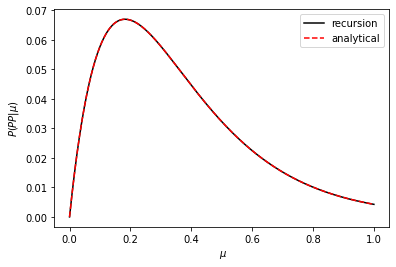

In [11]:
prob=[]
prob_a=[]
for u in np.linspace(0,1,1000):
    prob.append(get_prob( u))
    prob_a.append((1-np.exp(-u*1))**1*(np.exp(-u*1))**5)
plt.plot(np.linspace(0,1,1000), 10**-np.array(prob),color='black',label='recursion')
plt.plot(np.linspace(0,1,1000), prob_a,linestyle='dashed',color='red',label='analytical')
plt.xlabel(r" $\mu$")
plt.ylabel(r"$P(PP|\mu)$")
plt.legend()
plt.show()

In [12]:
u=m[0]

In [13]:
(1-np.exp(-u*1))*(np.exp(-u*1))**5

0.06697959484126674

## Test case of a two losses, with closed-form probability

In [14]:
t=ete3.Tree("((A:1,B:1):1,(C:1,D:1):1);")
tmap={'A':1,'B':0,'C':0,'D':1}
for x in t:
    if x.is_leaf():
        x.p1=int(tmap[x.name]==1)
        x.p0=int(tmap[x.name]==0)

In [15]:

m= scipy.optimize.fmin(get_prob, x0=.10)

Optimization terminated successfully.
         Current function value: 1.658608
         Iterations: 17
         Function evaluations: 34


In [16]:
10**-1.658608

0.02194785083893017

/tmp/ipykernel_2534622/3897918740.py:48: RuntimeWarning: divide by zero encountered in log10
  return -np.log10(te.p1)


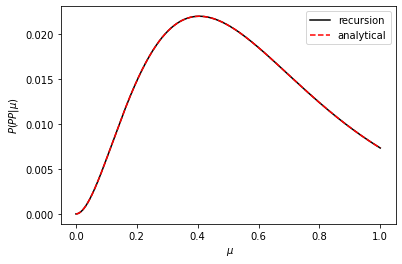

In [17]:
prob=[]
prob_a=[]
for u in np.linspace(0,1,1000):
    prob.append(get_prob( u))
    prob_a.append((1-np.exp(-u*1))**2*(np.exp(-u*1))**4)
plt.plot(np.linspace(0,1,1000), 10**-np.array(prob),color='black',label='recursion')
plt.plot(np.linspace(0,1,1000), prob_a,linestyle='dashed',color='red',label='analytical')
plt.xlabel(r" $\mu$")
plt.ylabel(r"$P(PP|\mu)$")
plt.legend()
plt.show()

## Obtain probability of phyletic pattern with presence in collembola and sciaridae only

In [3]:
##load hexapod tree (Misof et al for non-dipteran orders, and Wiegmann et al for Diptera), copied from "outputs/final_concatenated_arthropod_order_collapsed_diptera.nwk"
t=ete3.Tree('((((((((((Lepidoptera:207.201,Trichoptera:207.201):82.4488,(((Psychodidae:234.213,Culicomorpha:234.213):3.5763,((Stratiomyidae:202.026,Muscomorpha:202.026):26.9598,(Sciaridae:117.57,Cecidomyiidae:117.57):111.416):8.80321):4.95369,Siphonaptera:242.743):46.9067):37.0421,(Coleoptera:307.709,Neuroptera:307.709):18.983):17.9882,Hymenoptera:344.68):16.8525,Psocodea:361.532):11.7545,(Hemiptera:339.128,Thysanoptera:339.128):34.1591):13.6024,((Blattodea:231.271,Phasmatodea:231.271):16.5734,Orthoptera:247.845):139.045):19.5621,(Ephemeroptera:362.454,Odonata:362.454):43.9968):14.0978,Zygentoma:420.549):58.5756,(Symphypleona:242.695,Entomobryomorpha:242.695):236.43);')

In [4]:
print(t)


                              /-Lepidoptera
                           /-|
                          |   \-Trichoptera
                          |
                          |         /-Psychodidae
                          |      /-|
                        /-|     |   \-Culicomorpha
                       |  |     |
                       |  |   /-|      /-Stratiomyidae
                       |  |  |  |   /-|
                       |  |  |  |  |   \-Muscomorpha
                       |  |  |   \-|
                     /-|   \-|     |   /-Sciaridae
                    |  |     |      \-|
                    |  |     |         \-Cecidomyiidae
                    |  |     |
                    |  |      \-Siphonaptera
                  /-|  |
                 |  |  |   /-Coleoptera
                 |  |   \-|
               /-|  |      \-Neuroptera
              |  |  |
              |  |   \-Hymenoptera
            /-|  |
           |  |   \-Psocodea
           |  |
           |  |   /

In [5]:
t.prune([x.name for x in t if x.name!='Symphypleona'],preserve_branch_length=True)

In [6]:

for x in t:
    if x.is_leaf():
        if 'Entomobryomorpha' in x.name or 'Sciaridae' in x.name:
          
            x.p0=0
            x.p1=1
        else:
            x.p1=0
            x.p0=1


In [7]:
import scipy

In [8]:

m= scipy.optimize.fmin(get_prob, x0=.01)

Optimization terminated successfully.
         Current function value: 4.101650
         Iterations: 9
         Function evaluations: 18


In [9]:
p=10**-4.101650

In [10]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")


from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

In [11]:
N=20e3
import numpy as np
N,p*N, np.sqrt(p*(1-p)*N)

(20000.0, 1.5826321930451033, 1.2579773276224735)

In [12]:
import pandas as pd
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col='accession')
hgt=dfriso[dfriso.tree_HTG]
observed_DIAMOND=hgt[hgt['class']=="Collembola"].shape[0]

In [13]:
observed_DIAMOND

785

In [16]:
dftree=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t",index_col=0)
##number of transfer events
observed_tree=dftree[dftree.annotation.isin(["One step","Two step"])&(dftree['primary neighbor']=="Collembola")].shape[0]

In [17]:
observed_tree

386

In [18]:
p*20e3

1.5826321930451033

/tmp/ipykernel_1224819/1484512997.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo" (-> color='b'). The keyword argument will take precedence.
  plt.plot(x, binom.pmf(x, N, p), 'bo', ms=5, label='Expectation under loss', color='black')


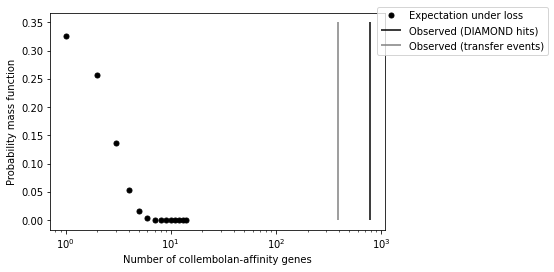

In [19]:
from scipy.stats import binom

x = np.arange(1,
              15)
plt.plot(x, binom.pmf(x, N, p), 'bo', ms=5, label='Expectation under loss', color='black')
plt.vlines(observed_DIAMOND,0,.35,color='black',label='Observed (DIAMOND hits)')
plt.vlines(observed_tree,0,.35,color='grey',label='Observed (transfer events)')
plt.xlabel('Number of collembolan-affinity genes') 
plt.ylabel('Probability mass function')
plt.xscale('log')
plt.legend(bbox_to_anchor=(1.5, 1.05))
plt.savefig('figures/gene_loss_model_result_v3.svg', format='svg',bbox_inches='tight')
plt.show()